# German day-ahead price forecast

## Objective

A German manufacturer runs one 8-hour shift a day and buys 500 MWh for it, 62.5 MW in each hour. At 11:55 on D-1, five minutes before the day-ahead auction closes, it picks when tomorrow's shift starts, anywhere from 00:00 to 16:00, to make electricity plus staff premiums as cheap as possible. This notebook builds the price forecast it picks from. The full case is in `project.md`.

| | |
|---|---|
| Target | `price_da`, the DE-LU day-ahead clearing price in EUR/MWh, one row per delivery hour |
| Predict or explain | Predict. The model is judged on held-out error, and its coefficients are a by-product |
| Forecast moment | 11:55 German time on D-1, 12 to 36 hours ahead. Nothing published after that may be a feature |
| The decision | `shift cost = mean(price_h + premium_h)` over the 8 shift hours, in EUR/MWh. `premium_h` is 10 EUR/MWh (625 EUR of extra staff cost an hour, spread over 62.5 MWh) from 22:00 to 06:00 and in every weekend hour, otherwise 0 |
| What an error costs | Only which shift wins changes the purchase. The size of the price differences matters, not only their order: a cheap hour is not worth it if it pulls expensive neighbours into the shift. A forecast 20 EUR/MWh too high in every hour still costs nothing |
| Metrics | MAE and RMSE for the course, MASE against same-hour-yesterday so years at different price levels compare. The decision metric is the cost of the chosen shift against a standard 06:00 to 14:00 shift and against perfect hindsight |
| Simplifications | Shifts stay within one day, though a real shift can cross midnight. The weekend premium applies to every hour, so it adds to the cost but never changes which weekend shift wins |


Load the libraries and the three fetch functions, and set the plot and table display defaults.


In [1]:
import polars as pl
from plotnine import (
    aes,
    element_text,
    facet_wrap,
    geom_col,
    geom_hline,
    geom_line,
    geom_point,
    geom_text,
    geom_tile,
    ggplot,
    labs,
    scale_fill_gradient,
    scale_x_continuous,
    theme,
    theme_minimal,
    theme_set,
)

from data_schemas import CombinedDataSchema
from spot_price_forecast import fetch_de_prices, fetch_forecasts, fetch_neighbor_prices

# legend on top: a legend on the right sits past the pane edge when the plot is wide
theme_set(theme_minimal() + theme(figure_size=(10, 4.5), legend_position="top"))
# a kernel has no terminal, so polars would squeeze every table into ~100 characters
_ = (
    pl.Config.set_tbl_rows(30)
    .set_tbl_cols(-1)  # show every column
    .set_tbl_width_chars(1000)  # wide tables use the pane instead of wrapping
    .set_fmt_str_lengths(60)
    .set_float_precision(3)
)

## 1. Raw data

`refresh=True` on any of the three pulls it again from the Energy-Charts API. The files hold
what the API served, untouched.


Load the three raw datasets from `data/`, pulling from the API only if a file is missing.


In [2]:
prices_raw = fetch_de_prices()
forecasts_raw = fetch_forecasts()
neighbors_raw = fetch_neighbor_prices()

## 2. Parse and join

Mechanical fixes only, the same for every file:

1. Every file is averaged to UTC hours. Prices go quarter-hourly on 2025-10-01 and the forecasts are quarter-hourly throughout, so the mean puts all three on one grid. It also fills Switzerland, which stays hourly and leaves three of every four quarter-hours empty.
2. The join starts from the price table, so every row has a target.
3. Calendar columns are in German local time, because demand follows the local clock.
4. `fc_residual` is load minus solar and wind, as defined in `project.md`.
5. The result is validated against the data model in `data_schemas.py`. Read that file for what the table holds.


Average every file to UTC hours.


In [3]:
def to_hourly(raw: pl.DataFrame) -> pl.DataFrame:
    return (
        raw.sort("utc_timestamp")
        .group_by_dynamic("utc_timestamp", every="1h")
        .agg(pl.all().mean())
    )


prices = to_hourly(prices_raw)
forecasts = to_hourly(forecasts_raw)
neighbors = to_hourly(neighbors_raw)

Join the forecasts and neighbour prices onto the price table by timestamp.


In [4]:
joined = prices.join(forecasts, on="utc_timestamp", how="left").join(
    neighbors, on="utc_timestamp", how="left"
)

Add the German date, year, hour of day and weekday, and residual load.


In [5]:
local = pl.col("utc_timestamp").dt.convert_time_zone("Europe/Berlin")

merged = joined.with_columns(
    date=local.dt.date(),
    year=local.dt.year(),
    hour=local.dt.hour(),
    weekday=local.dt.weekday(),
    fc_residual=pl.col("fc_load")
    - pl.sum_horizontal("fc_solar", "fc_wind_onshore", "fc_wind_offshore"),
)

Validate the merged table against the data model, which casts the types and drops unlisted columns.


In [6]:
df = CombinedDataSchema.validate(merged)
df.head(3)

utc_timestamp,price_da,fc_load,fc_solar,fc_wind_onshore,fc_wind_offshore,price_FR,price_NL,price_DK1,price_DK2,price_AT,price_PL,price_CH,price_BE,price_CZ,price_SE4,price_NO2,date,year,hour,weekday,fc_residual
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,date,i32,i8,i8,f64
2018-12-31 23:00:00 UTC,28.320,43213.150,0.000,18879.800,5068.875,51.000,68.920,28.320,28.320,33.480,23.395,50.260,69.490,8.500,28.320,48.770,2019-01-01,2019,0,2,19264.475
2019-01-01 00:00:00 UTC,10.070,41275.500,0.000,20626.575,5042.450,46.270,64.980,10.070,10.070,39.760,10.034,48.740,66.580,3.970,10.070,49.250,2019-01-01,2019,1,2,15606.475
2019-01-01 01:00:00 UTC,-4.080,40187.725,0.000,22355.675,5028.400,39.780,60.270,-4.080,-4.080,39.780,10.022,47.240,65.070,4.700,10.030,49.170,2019-01-01,2019,2,2,12803.650


Validation passed. The first row is midnight on 2019-01-01 German time, which is 23:00 UTC the day before.


The averaging has to come before the join: at raw resolution, three in four forecast rows before October 2025 would have no price to join to.


## 3. Split

Chronological by delivery date, with two validation folds so hyperparameters are chosen on more than one year:

| Fold | Train | Validate |
|---|---|---|
| 1 | 2019 to 2022 | 2023 |
| 2 | 2019 to 2023 | 2024 |

Fold scores are averaged in MASE, since 2023 and 2024 sit at different price levels. The chosen model is then refit on 2019 to 2024 and scores the test set, 2025 onward, once.

Exploration below uses 2019 to 2023, everything fold 2 trains on. That makes fold 1's score slightly optimistic: the features are shaped partly by looking at 2023, its validation year. Fold 2's 2024 was never explored.


Define the two folds and the test set, and show the size and dates of each.


In [7]:
LAST_EXPLORED_YEAR = 2023
TEST_FROM = 2025
FOLDS = {
    "fold-1": 2023,
    "fold-2": 2024,
}  # fold name: validation year, trained on all years before it

# exploration works on everything fold 2 trains on
train = df.filter(pl.col("year") <= LAST_EXPLORED_YEAR)
test = df.filter(pl.col("year") >= TEST_FROM)
folds: dict[
    str,
    tuple[pl.DataFrame, pl.DataFrame],
] = {
    name: (df.filter(pl.col("year") < year), df.filter(pl.col("year") == year))
    for name, year in FOLDS.items()
}


# one row per piece: each fold's training and validation data, then the test set
pieces: list[
    tuple[
        str,
        pl.DataFrame,
    ]
] = [
    (f"{name}-{role}", part)
    for name, (fit, valid) in folds.items()
    for role, part in (("train", fit), ("validate", valid))
] + [("test", test)]

pl.DataFrame(
    [
        {
            "set": label,
            "hours": part.height,
            "first_day": part["date"].min(),
            "last_day": part["date"].max(),
        }
        for label, part in pieces
    ]
)

set,hours,first_day,last_day
str,i64,date,date
"""fold-1-train""",35064,2019-01-01,2022-12-31
"""fold-1-validate""",8760,2023-01-01,2023-12-31
"""fold-2-train""",43824,2019-01-01,2023-12-31
"""fold-2-validate""",8784,2024-01-01,2024-12-31
"""test""",15575,2025-01-01,2026-10-11


Train covers three markets: calm (2019 to 2020), the gas crisis (2021 to 2022) and the recovery (2023). Fold 1 validates on the first year after the crisis and fold 2 on a calm one, so a setting has to work in both. Only test contains quarter-hour auctions.


## 4. Exploration

### 4.1 Dataset structure

The data model already tests gaps, duplicates and limits. These cells only describe the structure.


Summarise each raw file: rows, date range, duplicate timestamps and where quarter-hour data starts.


In [8]:
# one row per raw file. quarter_hourly_from is the first timestamp that comes
# 15 minutes after the one before it, which is where the file changes resolution
pl.concat(
    [
        raw.select(
            file=pl.lit(name),
            rows=pl.len(),
            first=pl.col("utc_timestamp").min(),
            last=pl.col("utc_timestamp").max(),
            duplicate_timestamps=pl.col("utc_timestamp").is_duplicated().sum(),
            quarter_hourly_from=pl.col("utc_timestamp")
            .filter(pl.col("utc_timestamp").diff() == pl.duration(minutes=15))
            .min(),
        )
        for name, raw in [
            ("prices", prices_raw),
            ("forecasts", forecasts_raw),
            ("neighbors", neighbors_raw),
        ]
    ]
)

file,rows,first,last,duplicate_timestamps,quarter_hourly_from
str,u32,"datetime[μs, UTC]","datetime[μs, UTC]",u32,"datetime[μs, UTC]"
"""prices""",95255,2018-12-31 23:00:00 UTC,2026-10-11 21:45:00 UTC,0,2025-09-30 22:15:00 UTC
"""forecasts""",272732,2018-12-31 23:00:00 UTC,2026-10-11 21:45:00 UTC,0,2018-12-31 23:15:00 UTC
"""neighbors""",95255,2018-12-31 23:00:00 UTC,2026-10-11 21:45:00 UTC,0,2025-09-30 22:15:00 UTC


No file has duplicate timestamps. Prices and neighbours turn quarter-hourly on 2025-10-01 German time, while the forecasts were quarter-hourly from the start, hence almost three times the rows.


Count the clock-change days, the forecast hours the join dropped, and the hits on the price floor.


In [9]:
hours_per_day = df.group_by("date").len()

pl.DataFrame(
    {
        "check": [
            "German days with 23 hours (spring clock change)",
            "German days with 25 hours (autumn clock change)",
            "forecast hours past the last cleared price (dropped)",
            "train hours at the -500 EUR/MWh auction floor",
        ],
        "count": [
            hours_per_day.filter(pl.col("len") == 23).height,
            hours_per_day.filter(pl.col("len") == 25).height,
            # forecast hours later than the last price, which the left join dropped
            forecasts.filter(
                pl.col("utc_timestamp") > df["utc_timestamp"].max()
            ).height,
            train.filter(pl.col("price_da") <= -500).height,
        ],
    }
)

check,count
str,i64
"""German days with 23 hours (spring clock change)""",8
"""German days with 25 hours (autumn clock change)""",7
"""forecast hours past the last cleared price (dropped)""",0
"""train hours at the -500 EUR/MWh auction floor""",1


8 spring and 7 autumn clock-change days, no forecast hours lost in the join, and the -500 floor hit once in train.


List the columns that have missing hours.


In [10]:
df.null_count().unpivot(variable_name="column", value_name="null_hours").filter(
    pl.col("null_hours") > 0
)

column,null_hours
str,u32
"""price_NL""",24


Only the Dutch price has gaps: 24 hours, all of 2026-10-10, most likely not yet published, so refresh before modelling. Nothing else needs fixing. On clock-change days the forecast vector is 23 or 25 long instead of 24, and the one floor hour needs no special handling.


How far each column is known at the 11:55 D-1 gate, from `project.md`. Everything is usable as a feature up to that point and nothing after it:

| Column | Known up to | Why |
|---|---|---|
| `price_da` (target) | end of D-1 | D-1 cleared in the auction on D-2, so lags of 24 h and more |
| `fc_load`, `fc_solar`, `fc_wind_*`, `fc_residual` | end of D, as a stand-in | The TSO's day-D forecast is published 18:00 D-1, after the gate. See below |
| `price_FR` ... `price_NO2` | end of D-1 | Day D clears in the same auction as DE-LU, so lags of 24 h and more |
| calendar | any date | Fixed in advance |

The `fc_*` columns are the TSOs' forecasts. They are computed at 08:00 D-1 but published at 18:00 D-1, six hours after the auction closes, so a trader bidding at 11:55 cannot see them and buys a forecast from a commercial vendor instead. Those are paid and we have no access, so the TSO forecast stands in for one. Both are made the same morning from the same weather models and should be close, but our errors could differ slightly from what a model fed a vendor forecast would get.

The data holds no actuals, which removes the most common leak in this problem.


### 4.2 The yearly mean price moves eightfold


Plot the daily mean price over the train period.


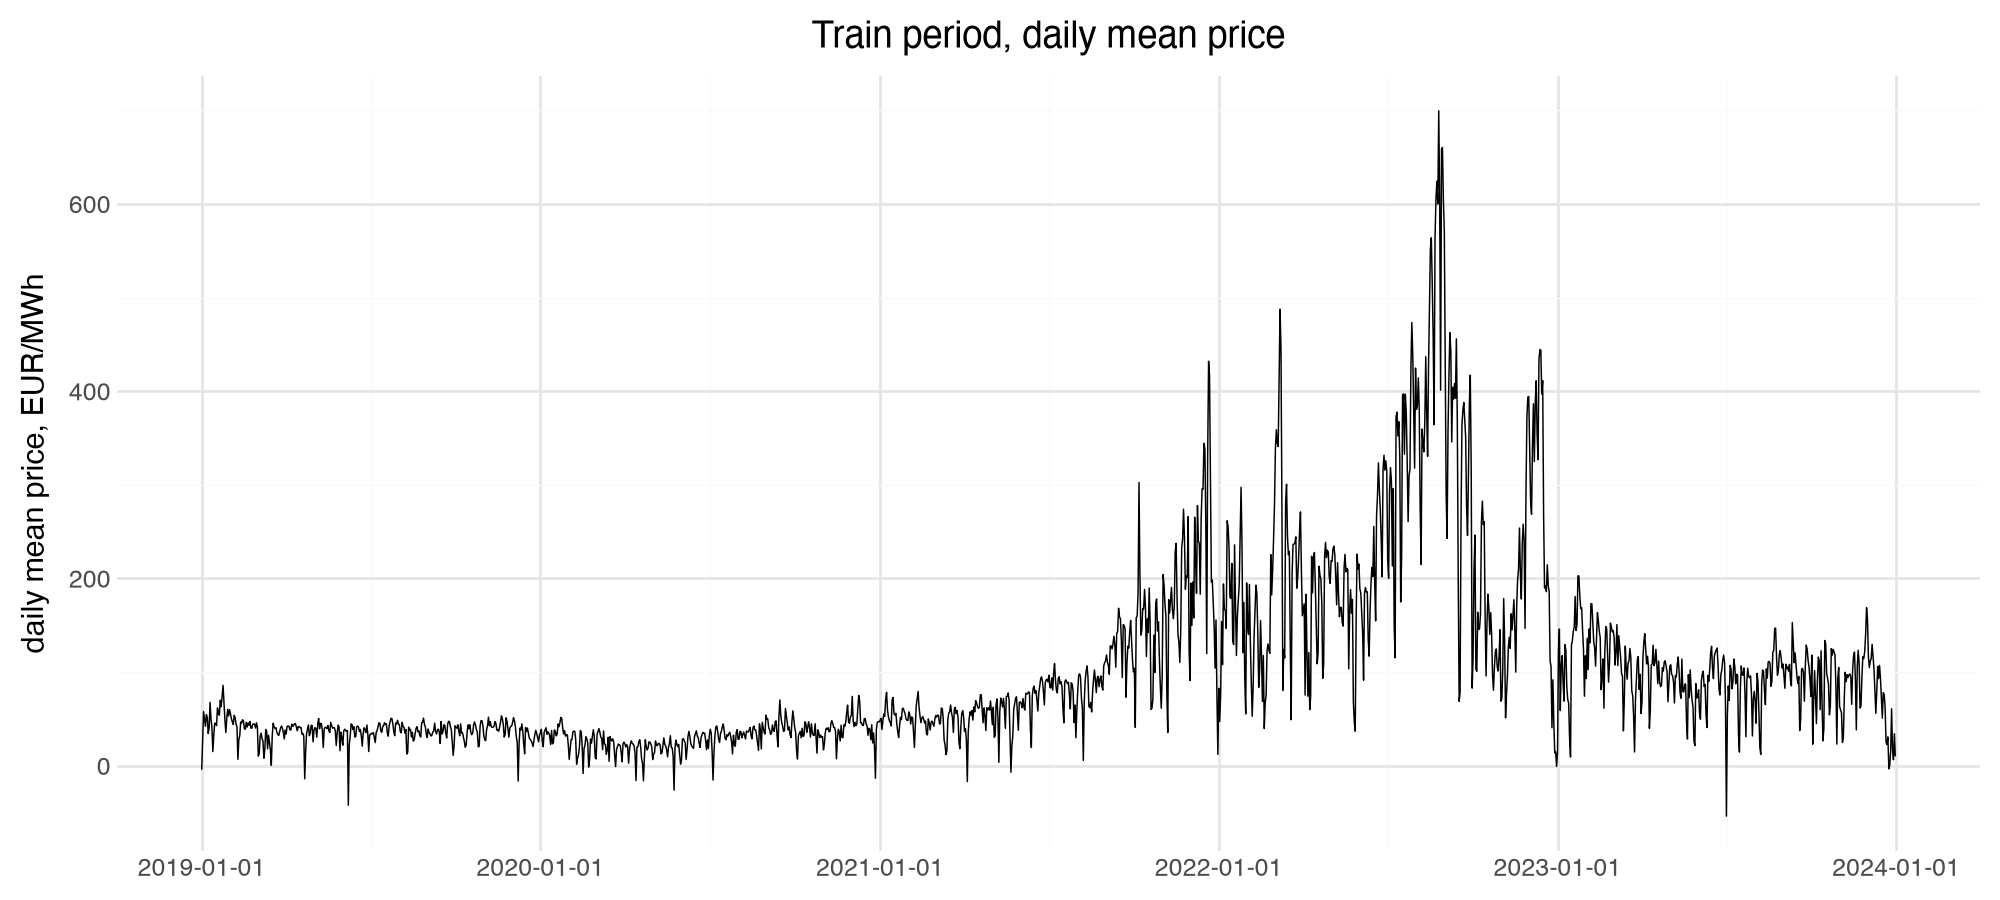

In [11]:
daily = train.group_by("date").agg(price=pl.col("price_da").mean()).sort("date")

(
    ggplot(daily, aes("date", "price"))
    + geom_line(size=0.3)
    + labs(x="", y="daily mean price, EUR/MWh", title="Train period, daily mean price")
)

The level never came back down after the crisis: 2023 averaged 95 EUR/MWh, two and a half times 2019's 38, so anything learned on the early years sits far too low.


Per year: the mean price, how much it swings, and the average miss of the two simplest forecasts.

- `mae_same_hour_yesterday`: forecast each hour with the price 24 hours earlier. `mean(|price_t - price_t-24|)`
- `mae_same_hour_last_week`: the price 168 hours (7 days) earlier. It compares a Monday with last Monday instead of with Sunday, so it catches the weekly cycle that the 24-hour version misses on Mondays and weekends.
- `yesterday_error_share`: `mae_same_hour_yesterday / mean_price`, the miss as a share of the year's price level.


In [12]:
# the miss of each naive forecast: each hour's price minus the price 24 or 168 hours earlier.
# the grid is hourly with no gaps, so differencing by rows is differencing by hours
miss_yesterday = pl.col("price_da").diff(24).abs()
miss_last_week = pl.col("price_da").diff(168).abs()

(
    train.with_columns(miss_yesterday=miss_yesterday, miss_last_week=miss_last_week)
    .group_by("year")
    .agg(
        mean_price=pl.col("price_da").mean(),
        sd_price=pl.col("price_da").std(),
        mae_same_hour_yesterday=pl.col("miss_yesterday").mean(),
        mae_same_hour_last_week=pl.col("miss_last_week").mean(),
    )
    .with_columns(
        yesterday_error_share=pl.col("mae_same_hour_yesterday") / pl.col("mean_price")
    )
    .sort("year")
)

year,mean_price,sd_price,mae_same_hour_yesterday,mae_same_hour_last_week,yesterday_error_share
i32,f64,f64,f64,f64,f64
2019,37.667,15.518,9.342,10.179,0.248
2020,30.471,17.501,9.994,10.314,0.328
2021,96.850,73.681,25.275,31.513,0.261
2022,235.446,142.809,58.190,87.078,0.247
2023,95.175,47.584,27.209,33.643,0.286


The naive forecast misses by 9 EUR/MWh in 2019 and 58 in 2022, yet always by 0.25 to 0.33 of that year's mean price. Same hour yesterday also beats same hour last week in every year. MAE alone cannot compare a CV fold that contains 2022 with a calm test year, which is why MASE goes beside it. No column measures fuel cost, so the level has to come from recent prices: lags, yesterday's mean and a longer moving average.


### 4.3 The decision only depends on the shape of the day

The company only chooses when its shift runs, and moving a whole day's prices up or down raises every possible shift by the same amount, which changes nothing it does. What matters is the variance within a day.


Split each year's price movement into two parts. Every hour's price is its day's mean price plus that hour's distance from the mean.

- `between_days_sd`: `sd(daily mean)`, how much whole days move up and down, in EUR/MWh. This is the level, which the decision cannot use.
- `within_day_sd`: `sd(price - its day's mean)`, how far a typical hour sits from its own day's mean, in EUR/MWh. This is the shape the decision ranks.
- `shape_share`: `within² / (within² + between²)`, the shape's share of all price movement. Squared because variances of the two parts add up to the total and SDs do not. At 0.2, four fifths (0.8) of the movement is whole days moving together. The share of the changes that can be attributed to the within day variation


In [13]:
# each hour's distance from its own day's mean price
around_daily_mean = train.with_columns(
    daily_mean=pl.col("price_da").mean().over("date"),
).with_columns(
    deviation=pl.col("price_da") - pl.col("daily_mean"),
)

(
    around_daily_mean.group_by("year")
    .agg(
        between_days_sd=pl.col("daily_mean").std(),
        within_day_sd=pl.col("deviation").std(),
    )
    .with_columns(
        shape_share=pl.col("within_day_sd") ** 2
        / (pl.col("within_day_sd") ** 2 + pl.col("between_days_sd") ** 2)
    )
    .sort("year")
)

year,between_days_sd,within_day_sd,shape_share
i32,f64,f64,f64
2019,11.840,10.030,0.418
2020,13.922,10.604,0.367
2021,66.936,30.798,0.175
2022,128.203,62.917,0.194
2023,35.887,31.247,0.431


In 2021 and 2022 the shape is only 0.18 to 0.19 of the price movement, against 0.37 to 0.43 in the other years: in 2022 whole days swung by 128 EUR/MWh while hours sat 63 from their day's mean.


Plot the average shape of the day for each year.


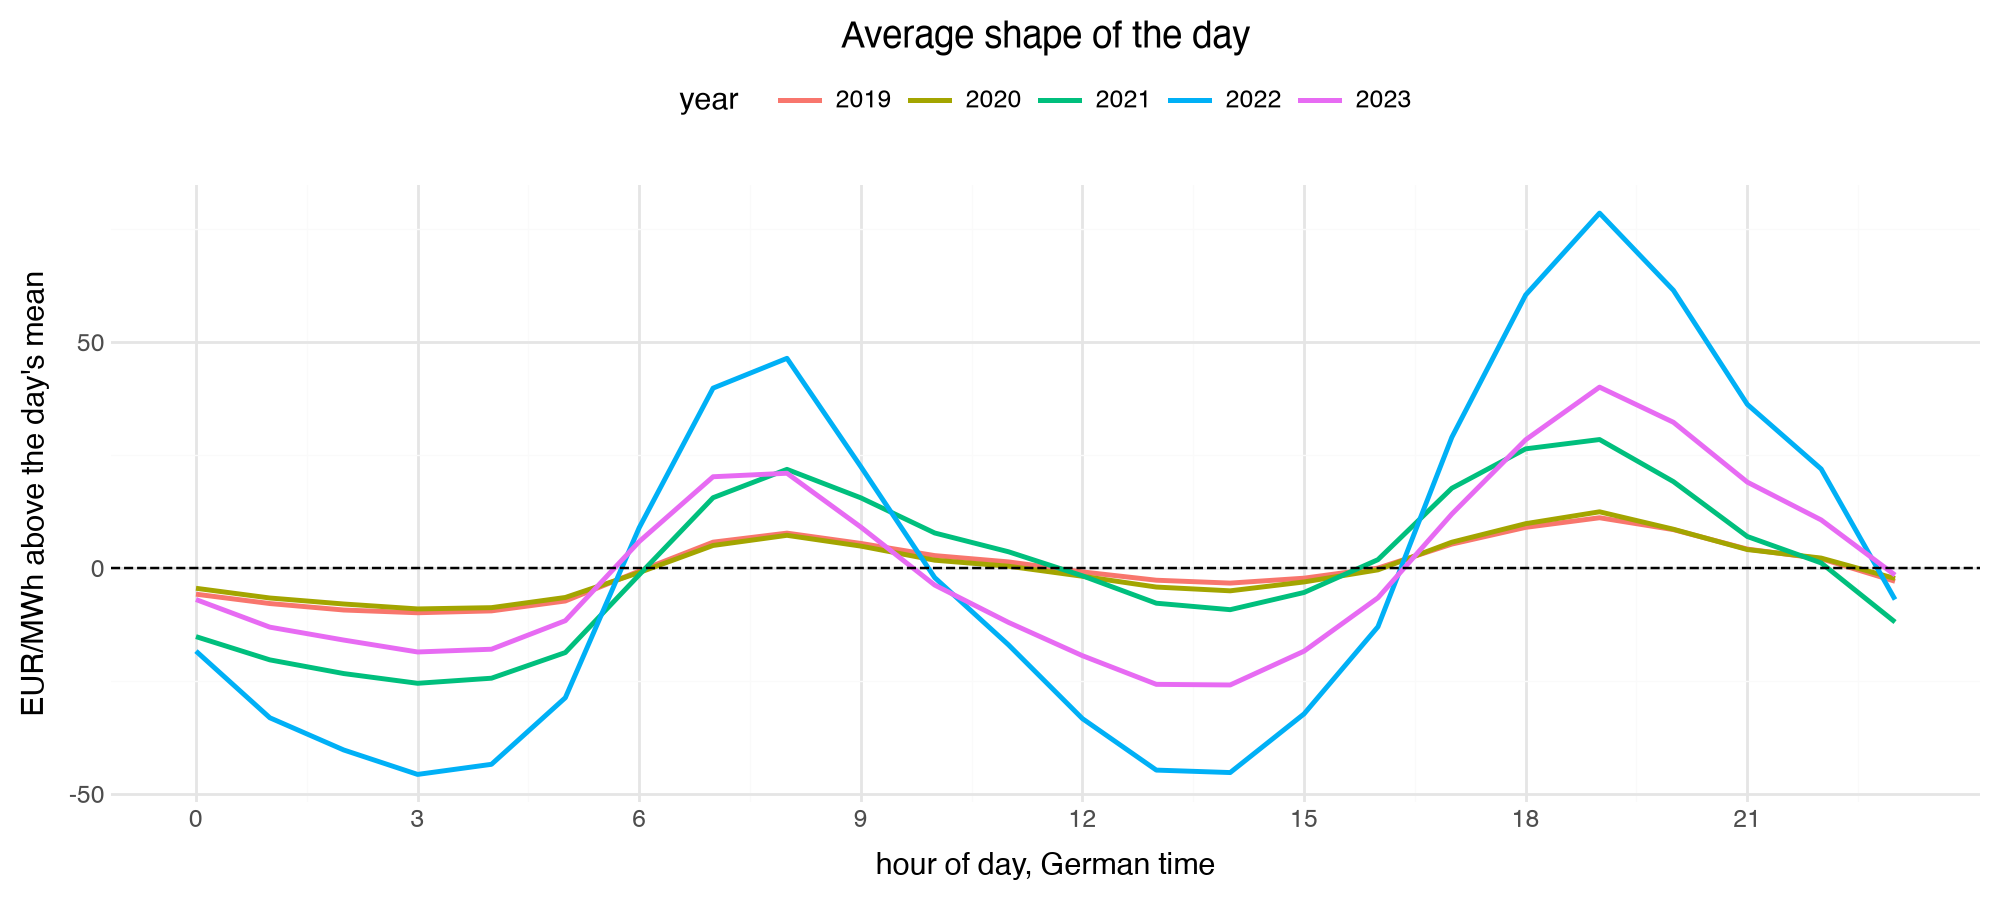

In [14]:
profile = (
    around_daily_mean.group_by("year", "hour")
    .agg(deviation=pl.col("deviation").mean())
    .with_columns(pl.col("year").cast(pl.String))
)

(
    ggplot(profile, aes("hour", "deviation", color="year"))
    + geom_line(size=1)
    + geom_hline(yintercept=0, linetype="dashed")
    + scale_x_continuous(breaks=range(0, 24, 3))
    + labs(
        x="hour of day, German time",
        y="EUR/MWh above the day's mean",
        title="Average shape of the day",
    )
)

The shape moved: by 2023 solar had pushed the cheapest hours from 03:00 to 13:00 to 14:00, so an hour-of-day effect learned on early years points at the wrong hours. The solar and residual-load forecasts have to carry that shift.

With the shape this small a share in the crisis years, a model that minimises error over all hours spends most of its effort on the level. The evaluation needs a shape measure too: the cost of the chosen shift, or the error left after removing each day's mean.


### 4.4 Residual load sets the shape, and its slope moves with the price level


Plot the median price against each forecast, one line per year.


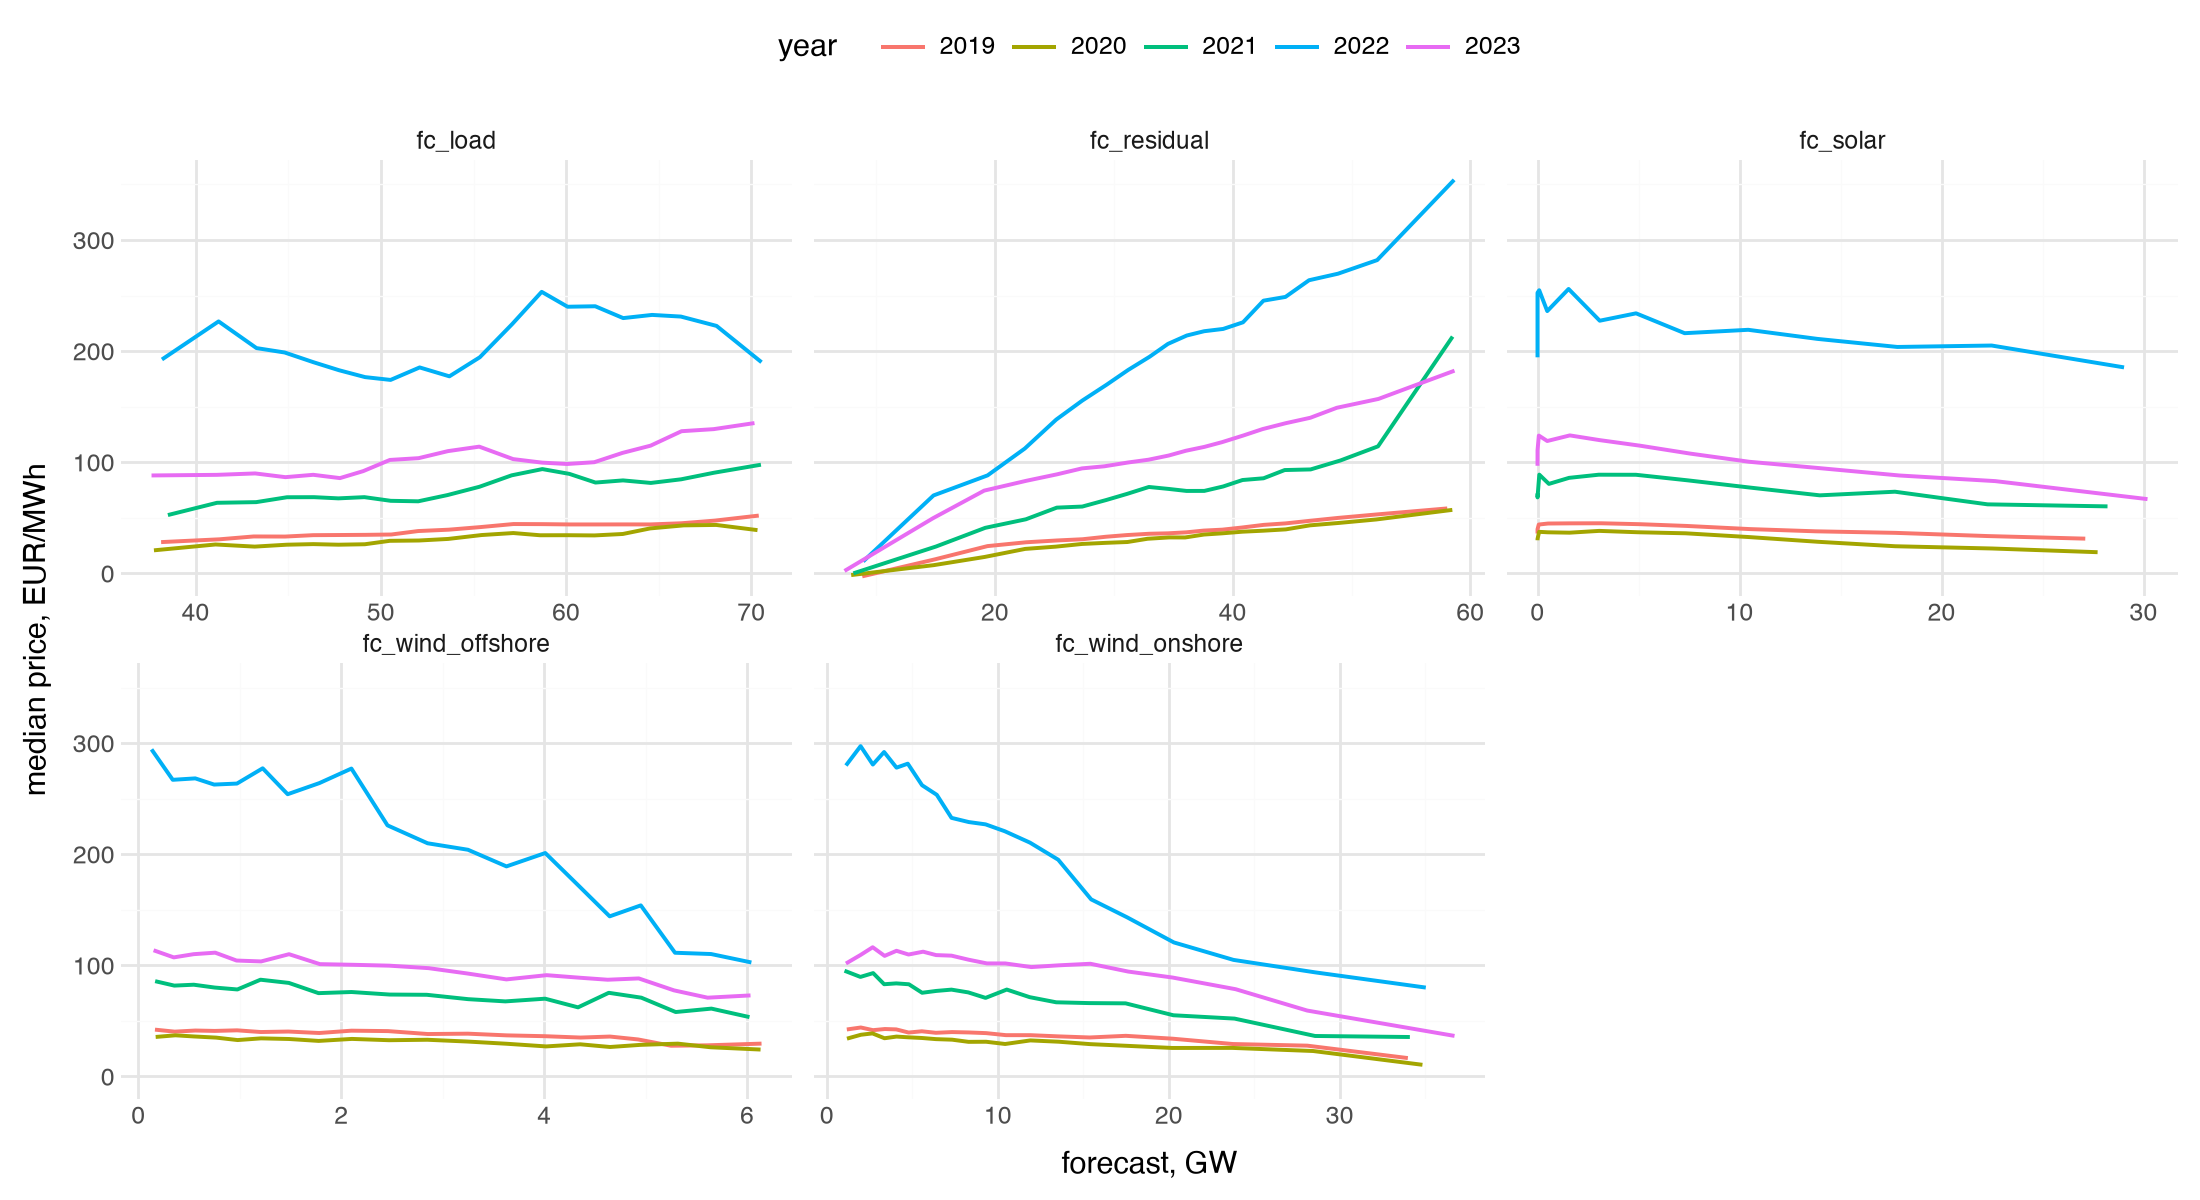

In [15]:
FORECASTS = [
    "fc_load",
    "fc_solar",
    "fc_wind_onshore",
    "fc_wind_offshore",
    "fc_residual",
]

merit = (
    # long format: one row per hour and forecast, so all five share one faceted plot
    train.unpivot(
        index=["year", "price_da"],
        on=FORECASTS,
        variable_name="forecast",
        value_name="mw",
    )
    # cut each forecast into 20 quantile bins with equal hour counts. solar is zero
    # every night, so its lowest quantiles coincide and merge into one bin
    .with_columns(
        bin=pl.col("mw").qcut(20, allow_duplicates=True).over("forecast"),
        year=pl.col("year").cast(pl.String),
    )
    .group_by("forecast", "year", "bin")
    .agg(
        gw=pl.col("mw").median() / 1000,
        price=pl.col("price_da").median(),
        hours=pl.len(),
    )
    .filter(pl.col("hours") >= 50)  # thin bins are noise
)

(
    ggplot(merit, aes("gw", "price", color="year"))
    + geom_line(size=0.8)
    + facet_wrap("~forecast", scales="free_x", ncol=3)
    + labs(x="forecast, GW", y="median price, EUR/MWh")
    + theme(figure_size=(11, 6))
)

Residual load is the only panel where every year's line climbs steadily, and how steeply it climbs changes from year to year. The 2021 line also bends upward above about 52 GW, a scarcity cliff no straight line follows.


Per year, three numbers on residual load and the price:

- `corr_all_hours`: correlation over every hour. It mixes the level and the shape.
- `corr_within_day`: `corr(price - day's mean price, residual - day's mean residual)`. Only asks whether a day's high-residual hours are also its expensive hours, the comparison within the day that the shift choice needs.
- `price_rise_per_gw`: `cov(price, residual) / var(residual) * 1000`, the slope of a straight-line fit: EUR/MWh added per extra GW of residual load.


In [16]:
# price and residual load as distances from their own day's mean
price_dev = pl.col("price_da") - pl.col("price_da").mean().over("date")
residual_dev = pl.col("fc_residual") - pl.col("fc_residual").mean().over("date")

# least-squares slope of price on residual load, scaled from MW to GW
residual_stats = {
    "corr_all_hours": pl.corr("price_da", "fc_residual"),
    "corr_within_day": pl.corr(price_dev, residual_dev),
    "price_rise_per_gw": pl.cov("price_da", "fc_residual")
    / pl.col("fc_residual").var()
    * 1000,
}

# the same three numbers per year, then once for all train years pooled
pl.concat(
    [
        train.group_by("year")
        .agg(**residual_stats)
        .sort("year")
        .with_columns(pl.col("year").cast(pl.String)),
        train.select(year=pl.lit("2019-2023"), **residual_stats),
    ]
)

year,corr_all_hours,corr_within_day,price_rise_per_gw
str,f64,f64,f64
"""2019""",0.847,0.849,1.121
"""2020""",0.827,0.825,1.168
"""2021""",0.582,0.757,3.538
"""2022""",0.623,0.850,7.124
"""2023""",0.882,0.850,3.105
"""2019-2023""",0.387,0.696,3.213


Within the day the correlation holds at 0.76 to 0.85 every year, but the slope runs from 1.1 EUR/MWh per GW in 2019 to 7.1 in 2022, which is why pooling the years drops the all-hours correlation to 0.39.


Within-day correlation of each forecast with the price.


In [17]:
# the within-day correlation from the cell above, once per forecast
train.select(
    [
        pl.corr(price_dev, pl.col(c) - pl.col(c).mean().over("date")).alias(c)
        for c in FORECASTS
    ]
)

fc_load,fc_solar,fc_wind_onshore,fc_wind_offshore,fc_residual
f64,f64,f64,f64,f64
0.269,-0.288,-0.248,-0.150,0.696


Residual load drives the shape at 0.70 pooled, against at most 0.29 for any single component. Because its slope moves with the price level, a linear model needs residual load times a recent price level; trees find that on their own.


### 4.5 Price memory


Correlate the price with itself at every lag up to two weeks.


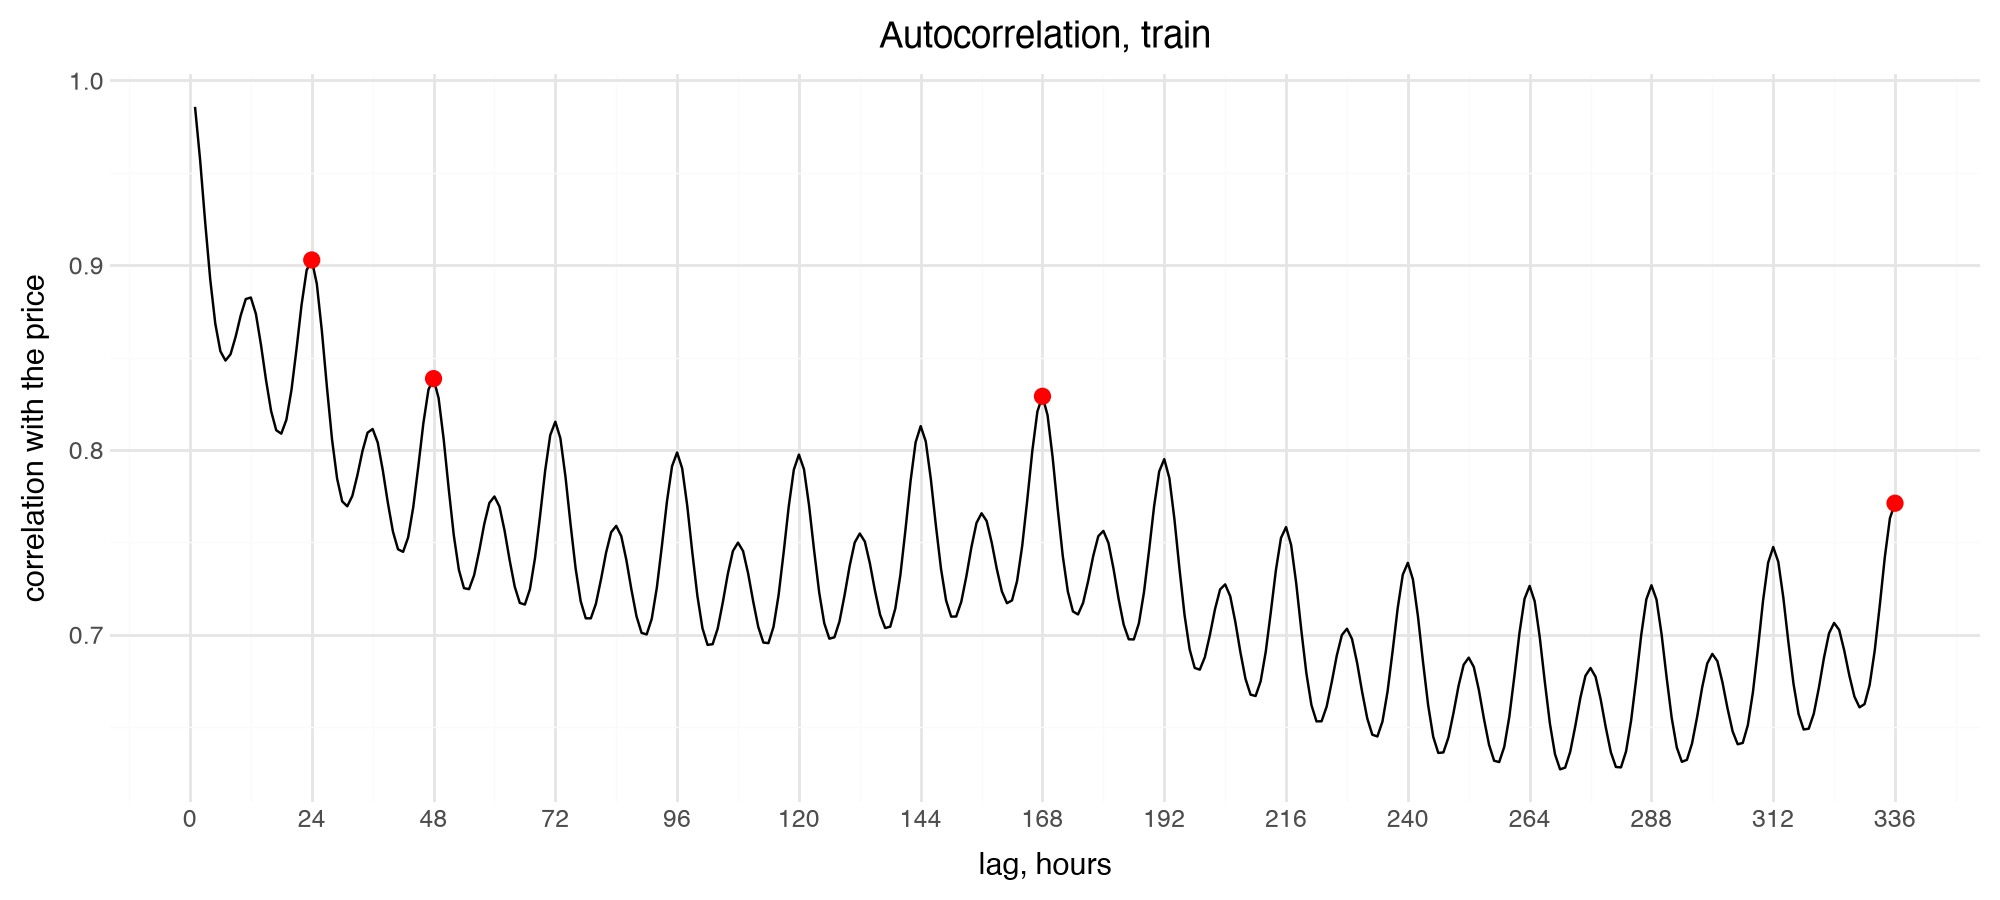

In [18]:
# correlation of the price with itself shifted k hours back, for every k up to 14 days
lags = range(1, 24 * 14 + 1)
autocorrelation = pl.DataFrame(
    {
        "lag_hours": list(lags),
        "corr": [
            train.select(pl.corr("price_da", pl.col("price_da").shift(k))).item()
            for k in lags
        ],
    }
)

(
    ggplot(autocorrelation, aes("lag_hours", "corr"))
    + geom_line()
    + geom_point(
        data=autocorrelation.filter(pl.col("lag_hours").is_in([24, 48, 168, 336])),
        color="red",
        size=2.5,
    )
    + scale_x_continuous(breaks=range(0, 24 * 14 + 1, 24))
    + labs(
        x="lag, hours", y="correlation with the price", title="Autocorrelation, train"
    )
)

Same hour yesterday (0.90) is the strongest legal lag, so it is the baseline. Every 24 hours the correlation peaks again, and the peak at 168 hours stands above its neighbours (0.83 against 0.81 at 144 and 0.80 at 192): that bump is the weekly cycle, a Monday resembling last Monday more than last Sunday. That makes lag 168 the second lag worth keeping.


### 4.6 Neighbouring zones

Same hour is a leak, shown only to measure coupling. Lag 24 is the legal version. Spread asks whether the gap between a zone and Germany on D-1 predicts Germany's move to day D.


Per zone, three correlations with the German price:

- `same_hour_LEAK`: with the zone's price in the same hour. Unknowable at the gate, shown only to measure how tightly the markets move together.
- `lag24`: with the zone's price 24 hours earlier, the legal version. Germany's own row is the number to beat.
- `spread_vs_change`: `corr(zone_t-24 - DE_t-24, DE_t - DE_t-24)`, whether yesterday's gap to the zone predicts Germany's move since yesterday. Positive means that when the zone was more expensive than Germany yesterday, Germany tends to rise.


In [19]:
NEIGHBORS = [c for c in df.columns if c.startswith("price_") and c != "price_da"]

# every price shifted back 24 hours, as new *_lag24 columns
lagged = train.with_columns(
    pl.col(["price_da", *NEIGHBORS]).shift(24).name.suffix("_lag24")
)
# how much the German price moved since the same hour yesterday
change = pl.col("price_da").diff(24)

pl.DataFrame(
    {
        "zone": ["DE-LU itself", *NEIGHBORS],
        "same_hour_LEAK": [
            None,
            *[lagged.select(pl.corr("price_da", z)).item() for z in NEIGHBORS],
        ],
        "lag24": [
            lagged.select(pl.corr("price_da", f"{z}_lag24")).item()
            for z in ["price_da", *NEIGHBORS]
        ],
        "spread_vs_change": [
            None,
            *[
                lagged.select(
                    pl.corr(change, pl.col(f"{z}_lag24") - pl.col("price_da_lag24"))
                ).item()
                for z in NEIGHBORS
            ],
        ],
    }
)

zone,same_hour_LEAK,lag24,spread_vs_change
str,f64,f64,f64
"""DE-LU itself""",null,0.903,null
"""price_FR""",0.934,0.886,0.244
"""price_NL""",0.971,0.903,0.284
"""price_DK1""",0.973,0.883,0.108
"""price_DK2""",0.943,0.858,0.107
"""price_AT""",0.967,0.903,0.255
"""price_PL""",0.858,0.792,0.228
"""price_CH""",0.935,0.894,0.315
"""price_BE""",0.971,0.904,0.277


Same-hour coupling runs from 0.80 (SE4) to 0.98 (CZ). A day back, the best zones (CZ 0.906, BE 0.904) only tie Germany's own lag 24 at 0.903. The spread correlates 0.11 to 0.32 with Germany's move.


Plot the same-hour price correlation between every pair of zones.


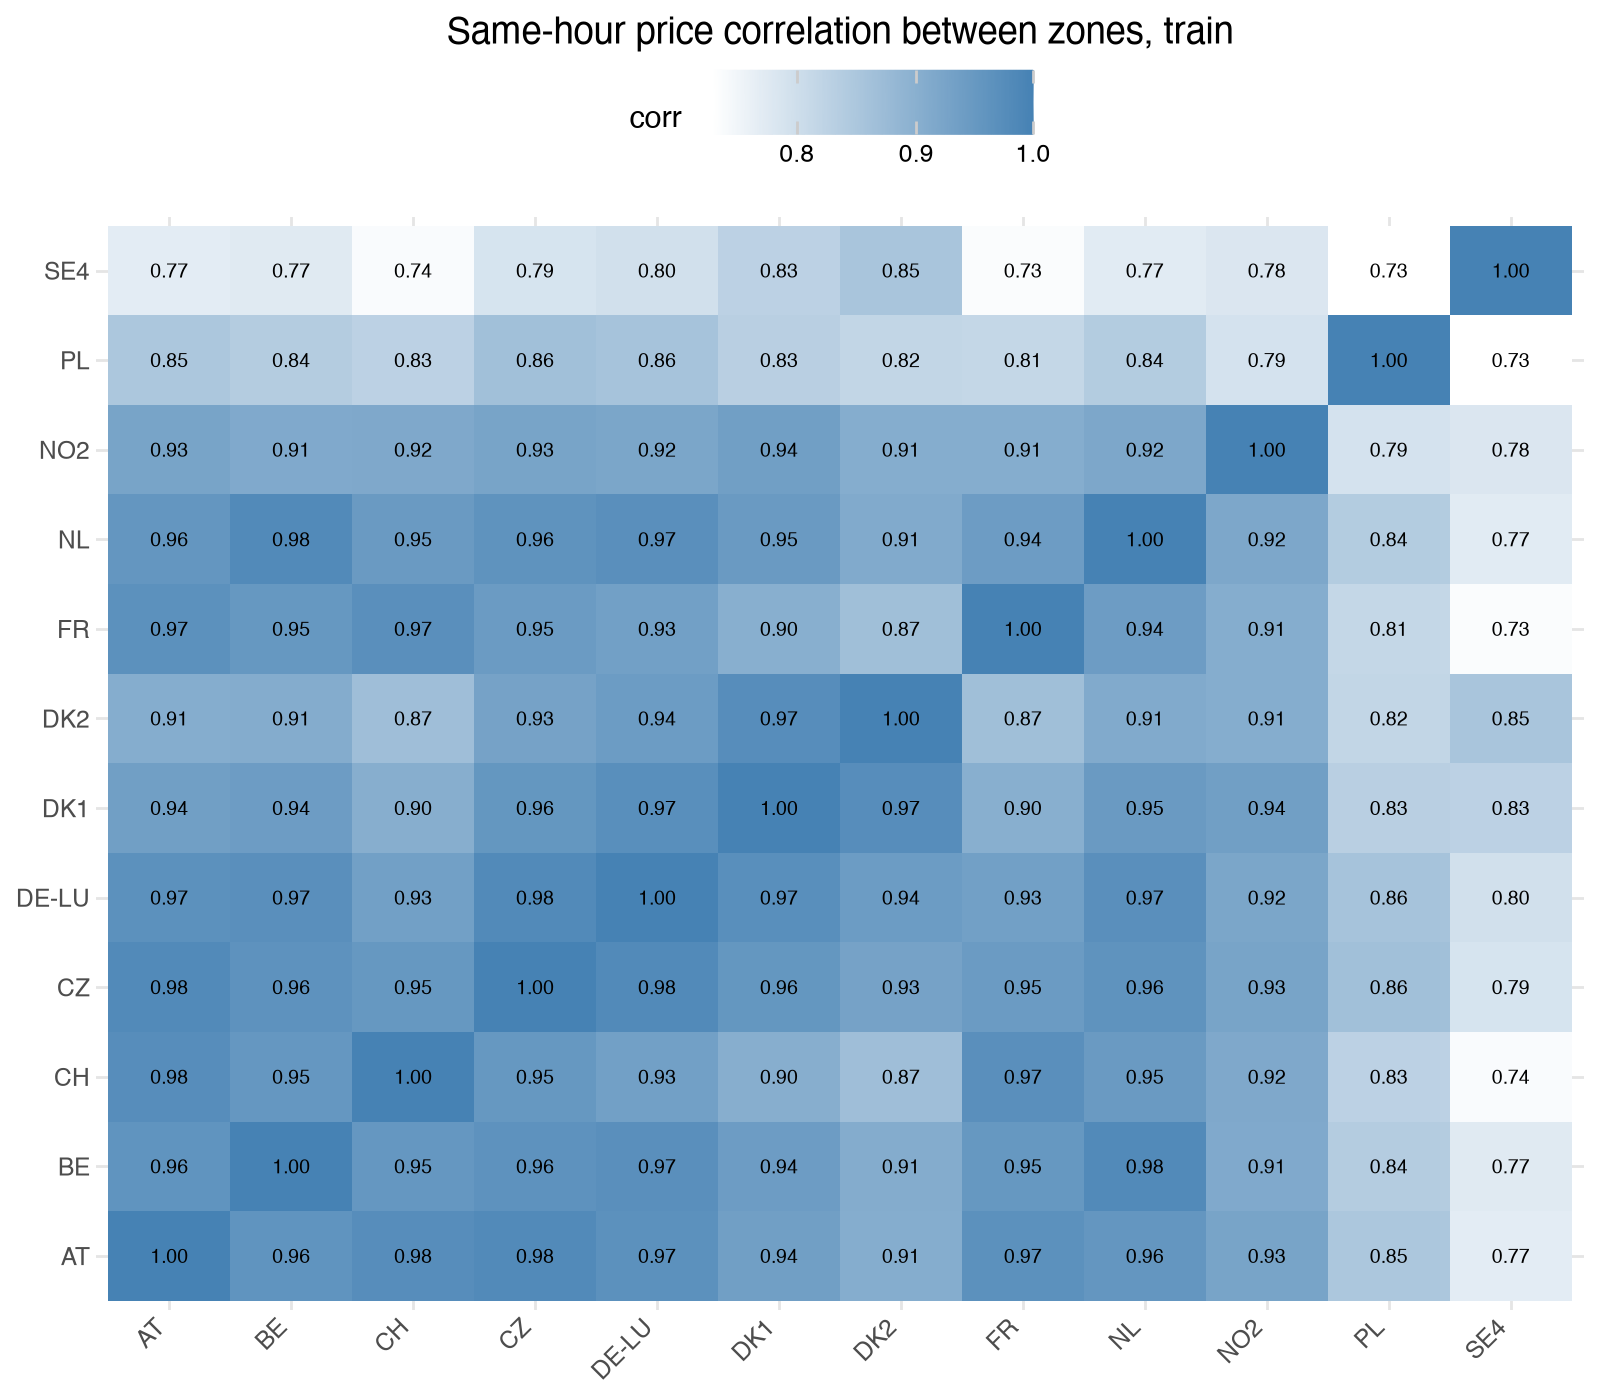

In [20]:
ZONES = ["price_da", *NEIGHBORS]
LABELS = ["DE-LU" if z == "price_da" else z.removeprefix("price_") for z in ZONES]
coupling = (
    train.select([pl.col(z).alias(label) for z, label in zip(ZONES, LABELS)])
    .drop_nulls()
    .corr()
    .with_columns(zone=pl.Series(LABELS))
    .unpivot(index="zone", variable_name="other", value_name="corr")
)

(
    ggplot(coupling, aes("zone", "other", fill="corr"))
    + geom_tile()
    + geom_text(aes(label="corr"), format_string="{:.2f}", size=7)
    + scale_fill_gradient(low="white", high="steelblue")
    + labs(x="", y="", title="Same-hour price correlation between zones, train")
    + theme(axis_text_x=element_text(rotation=45, ha="right"), figure_size=(8, 7))
)

Coupling this tight is what would make a same-hour neighbour price such a damaging leak. Lagged a day, neighbours only tie Germany's own lag 24, so plain neighbour lags add nothing.

The spread is the open question: it predicts Germany's move at up to 0.32 (Switzerland), but that may just be Germany reverting after a cheap day, which its own history already captures. A 15-minute check at the checkpoint settles it. For a linear model the central-western zones, at 0.94 to 0.98 with each other, are one variable repeated six times.


### 4.7 Negative prices


Count negative-price hours by hour of day.


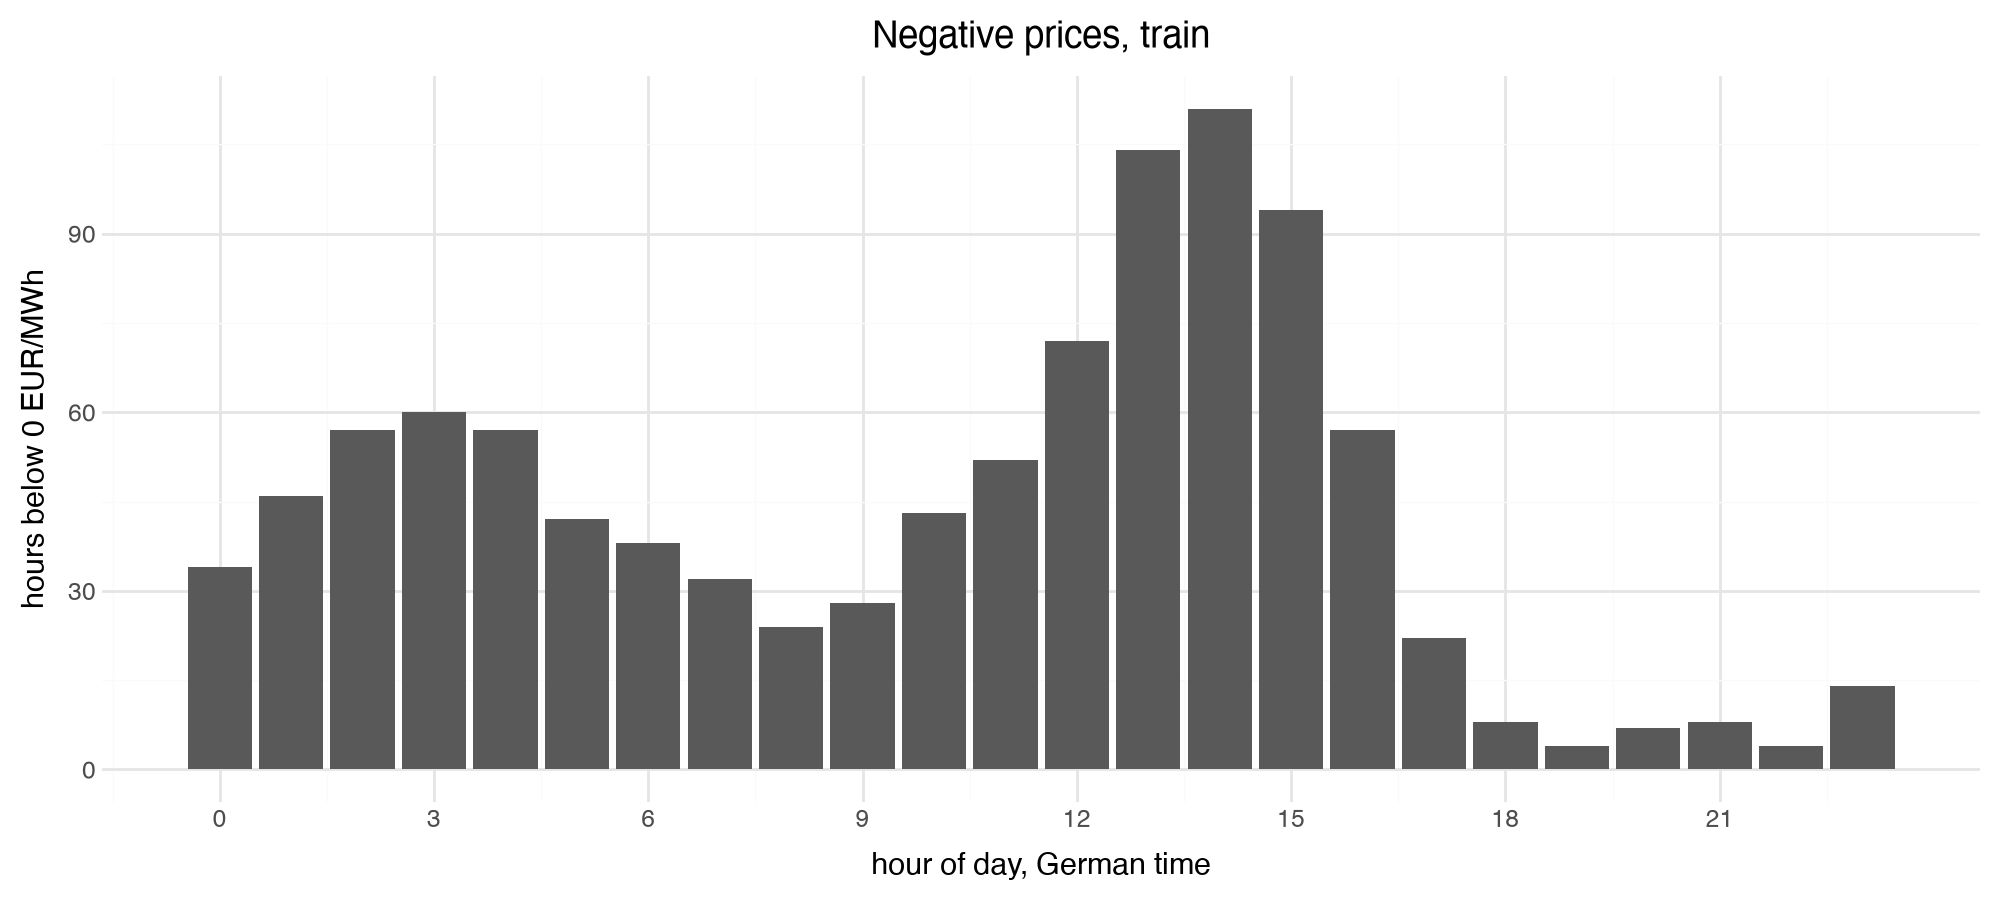

In [21]:
negatives = (
    train.group_by("hour")
    .agg(negative_hours=(pl.col("price_da") < 0).sum())
    .sort("hour")
)

(
    ggplot(negatives, aes("hour", "negative_hours"))
    + geom_col()
    + scale_x_continuous(breaks=range(0, 24, 3))
    + labs(
        x="hour of day, German time",
        y="hours below 0 EUR/MWh",
        title="Negative prices, train",
    )
)

Negative hours peak at 13:00 to 14:00, about 110 each over five years, with a smaller night peak around 03:00 at about 60.


Per year: negative hours, lowest and highest price.


In [22]:
train.group_by("year").agg(
    negative_hours=(pl.col("price_da") < 0).sum(),
    lowest=pl.col("price_da").min(),
    highest=pl.col("price_da").max(),
).sort("year")

year,negative_hours,lowest,highest
i32,u32,f64,f64
2019,211,-90.010,121.460
2020,298,-83.940,200.040
2021,139,-69.000,620.000
2022,69,-19.040,871.000
2023,301,-500.000,524.270


2023 had the most negative hours (301) and the one -500 hour; crisis 2022 had the fewest (69). Negative hours cluster at midday, which is solar, and at night, which is wind meeting low demand. Covering them in a shift pays least, because the company is paid to take the power, and the midday ones fall in the 09:00 to 10:00 starts that section 4.10 finds cheapest. A log transform cannot handle them; asinh can, if diagnostics later ask for a transform.


### 4.8 Calendar


Compare each weekday's mean price with the mean of its week. `eur_vs_week`: `mean(day's mean - week's mean)` in EUR/MWh. `share_of_weeks_cheaper`: share of weeks where that day sits below its week's mean.


In [23]:
(
    train.group_by("date", "weekday")
    .agg(daily_mean=pl.col("price_da").mean())
    # each day's distance from the mean of its calendar week
    .with_columns(week=pl.col("date").dt.truncate("1w"))
    .with_columns(
        vs_week=pl.col("daily_mean") - pl.col("daily_mean").mean().over("week")
    )
    # weekday 1 is Monday
    .group_by("weekday")
    .agg(
        eur_vs_week=pl.col("vs_week").mean(),
        share_of_weeks_cheaper=(pl.col("vs_week") < 0).mean(),
    )
    .sort("weekday")
)

weekday,eur_vs_week,share_of_weeks_cheaper
i8,f64,f64
1,5.136,0.396
2,12.110,0.222
3,11.212,0.230
4,9.454,0.211
5,3.909,0.310
6,-14.723,0.785
7,-27.078,0.893


Weekends lower the level: Sunday sits 27 EUR/MWh below its week, and below it in 0.89 of weeks. Weekday dummies cover that. Public holidays are not in the data and would look like ordinary weekdays to the model, which makes them a side exploration.


### 4.9 Collinearity among the forecasts


Correlation matrix of the five forecasts.


In [24]:
train.select(FORECASTS).corr().with_columns(forecast=pl.Series(FORECASTS)).select(
    "forecast", *FORECASTS
)

forecast,fc_load,fc_solar,fc_wind_onshore,fc_wind_offshore,fc_residual
str,f64,f64,f64,f64,f64
"""fc_load""",1.000,0.309,0.107,0.119,0.426
"""fc_solar""",0.309,1.000,-0.212,-0.195,-0.267
"""fc_wind_onshore""",0.107,-0.212,1.000,0.710,-0.610
"""fc_wind_offshore""",0.119,-0.195,0.710,1.000,-0.444
"""fc_residual""",0.426,-0.267,-0.610,-0.444,1.000


Only the two wind forecasts correlate (0.71), but `fc_residual` is an exact combination of the other four, so OLS cannot fit all five. Linear models take residual load and solar; trees can take all five.


### 4.10 Which shift simple rules would pick

The decision from the objective, in numbers, before any model exists: where the cheapest shift falls, and how much of the possible saving simple rules already get.


Define the night premium and the shift choice: for each day, the 8 consecutive hours with the lowest total score.


In [25]:
SHIFT_HOURS = 8
SHIFT_MW = 62.5  # 500 MWh a day over 8 hours
# extra staff cost per hour worked from 22:00 to 06:00 or at the weekend:
# about 25% on a crew costing 2,500 EUR an hour
PREMIUM_EUR_PER_HOUR = 625.0

# the premium spread over that hour's 62.5 MWh: 10 EUR/MWh
premium = (
    pl.when((pl.col("hour") >= 22) | (pl.col("hour") < 6) | (pl.col("weekday") >= 6))
    .then(PREMIUM_EUR_PER_HOUR / SHIFT_MW)
    .otherwise(0.0)
)


def best_shift(score: pl.Expr) -> pl.Expr:
    """True for the 8 consecutive hours of each day whose scores add up to the least."""
    position = pl.int_range(pl.len()).over("date")  # 0 for the first hour of the day
    # total over the 8 hours ending at each position. The first 7 hours have no full
    # window; they get infinity rather than null so arg_min counts positions correctly
    window_total = score.rolling_sum(SHIFT_HOURS).over("date").fill_null(float("inf"))
    # arg_min returns an unsigned integer, which would wrap below zero in shift_end - 8
    shift_end = window_total.arg_min().over("date").cast(pl.Int64)
    # a day with any missing score cannot be scheduled by that rule
    complete_day = score.is_not_null().all().over("date")
    return (position <= shift_end) & (position > shift_end - SHIFT_HOURS) & complete_day

Each rule picks a shift by its own score; every shift is then paid at the real cost.

- `cost`: `price + premium`, the effective EUR/MWh of an hour. The premium is 10 EUR/MWh at night and all weekend, 0 otherwise.
- `hindsight`: the day's actual cheapest shift, the best any forecast could do.
- `standard`: 06:00 to 14:00 every day, a normal early shift and the no-forecast reference.
- `fixed`: the shift that was cheapest on the previous year's average hourly price plus this day's premium. Missing for 2019, which has no previous year in the data.
- `yesterday`: the shift that would have been cheapest on D-1's prices at the same hours, plus the premium.
- `residual`: the shift with the lowest total forecast residual load. Residual load is in GW and cannot be added to a premium in euros, so this rule ignores the premium.
- `*_share`: `(standard - rule) / (standard - hindsight)`, the share of the possible saving a rule gets. 1 is as good as hindsight, 0 no better than the standard shift.


Mark the shift each rule picks on every training day.


In [26]:
RULES = ["hindsight", "standard", "fixed", "yesterday", "residual"]

# each hour's average price in the previous year, attached to the next year's rows
last_year_profile = (
    train.group_by("year", "hour")
    .agg(last_year_mean=pl.col("price_da").mean())
    .with_columns(pl.col("year") + 1)
)

shifts = (
    # lag before the join, since the join does not keep row order
    train.with_columns(price_lag24=pl.col("price_da").shift(24), premium=premium)
    .join(last_year_profile, on=["year", "hour"], how="left")
    .sort("utc_timestamp")
    .with_columns(
        cost=pl.col("price_da") + pl.col("premium"),
        standard=pl.col("hour").is_between(6, 13),
        hindsight=best_shift(pl.col("price_da") + pl.col("premium")),
        fixed=best_shift(pl.col("last_year_mean") + pl.col("premium")),
        yesterday=best_shift(pl.col("price_lag24") + pl.col("premium")),
        residual=best_shift(pl.col("fc_residual")),
    )
)

Plot how often the cheapest shift of the day starts at each hour, per year.


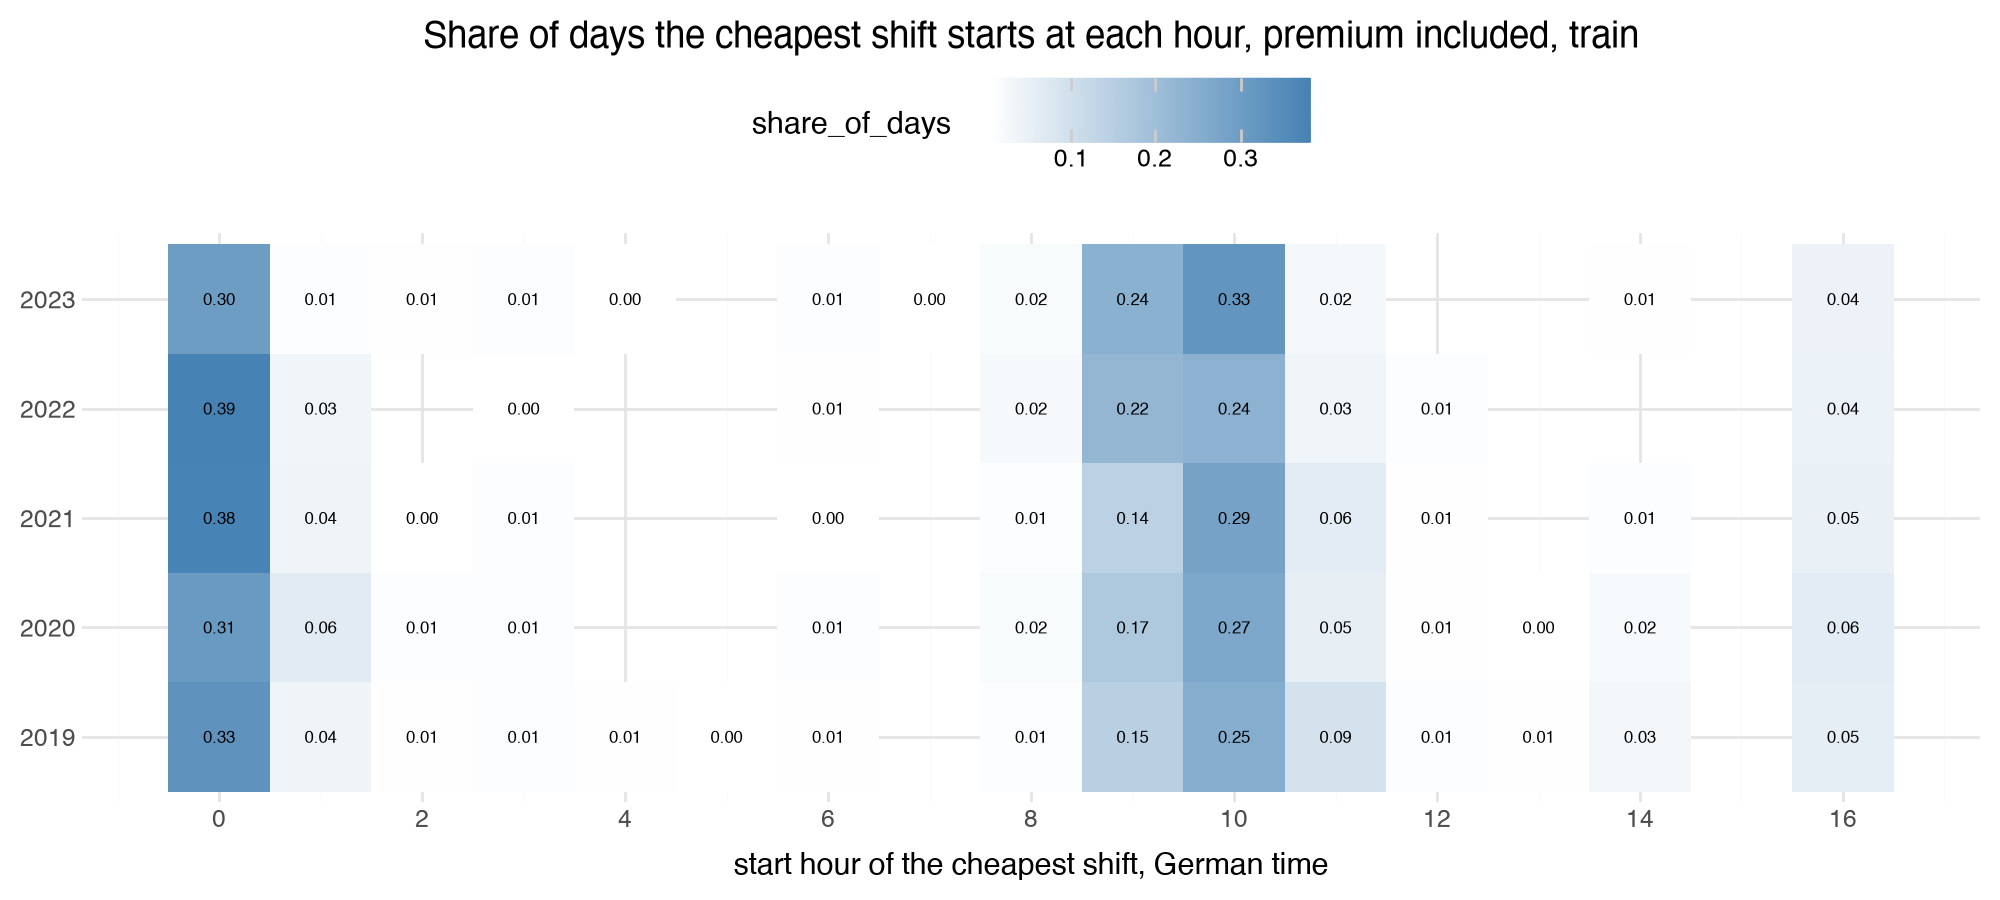

In [27]:
shift_starts = (
    shifts.filter(pl.col("hindsight"))
    .group_by("date")
    .agg(start_hour=pl.col("hour").first(), year=pl.col("year").first())
    .group_by("year", "start_hour")
    .agg(days=pl.len())
    .with_columns(
        share_of_days=pl.col("days") / pl.col("days").sum().over("year"),
        year=pl.col("year").cast(pl.String),
    )
)

(
    ggplot(shift_starts, aes("start_hour", "year", fill="share_of_days"))
    + geom_tile()
    + geom_text(aes(label="share_of_days"), format_string="{:.2f}", size=6)
    + scale_fill_gradient(low="white", high="steelblue")
    + scale_x_continuous(breaks=range(0, 17, 2))
    + labs(
        x="start hour of the cheapest shift, German time",
        y="",
        title="Share of days the cheapest shift starts at each hour, premium included, train",
    )
)

Two starts dominate: 00:00, on 0.30 to 0.39 of days, and 09:00 to 10:00, the solar midday, on 0.40 to 0.57 of days together. The standard 06:00 start is almost never cheapest, 0.01 of days at most.


Per year, the average cost per MWh of the shift each rule picks, and the share of the possible saving it gets.


In [28]:
shift_cost = shifts.group_by("year").agg(
    **{rule: pl.col("cost").filter(pl.col(rule)).mean() for rule in RULES}
)
shift_cost.with_columns(
    (
        (pl.col("standard") - pl.col(rule)) / (pl.col("standard") - pl.col("hindsight"))
    ).alias(f"{rule}_share")
    for rule in ("fixed", "yesterday", "residual")
).sort("year")

year,hindsight,standard,fixed,yesterday,residual,fixed_share,yesterday_share,residual_share
i32,f64,f64,f64,f64,f64,f64,f64,f64
2019,35.975,42.831,null,38.972,36.881,null,0.563,0.868
2020,28.214,34.802,33.104,31.388,28.909,0.258,0.518,0.895
2021,82.436,106.324,100.157,90.210,83.245,0.258,0.675,0.966
2022,192.233,240.849,223.535,206.195,194.252,0.356,0.713,0.958
2023,74.546,97.416,85.136,81.395,76.151,0.537,0.701,0.930


The residual-load rule gets 0.87 to 0.97 of the possible saving, yesterday's prices 0.52 to 0.71, and last year's average 0.26 to 0.54. In 2023 the cheapest shift cost 74.5 EUR/MWh, the standard shift 97.4 and the rule's pick 76.2, leaving 1.6 EUR/MWh on the table.

The rule is still strong but no longer close to perfect: it misses 0.03 to 0.13 of the saving, most in the calm years 2019 and 2020, when the 10 EUR/MWh premium is large next to the price gaps and the rule cannot see it. That is the room a price forecast has, since it can weigh the premium in euros.


## 5. Checkpoint

Phase 1 was reviewed on 2026-10-14. Sections 6 and 7, cleaning and features, are kept from a first phase 2 run; the models wait for the revised phase 2 process.

### Discoveries, ranked by how much they should change the model

1. Picking the shift with the lowest forecast residual load already gets 0.87 to 0.97 of the possible saving against a standard 06:00 shift, but it cannot weigh the night premium. A model is judged by the cost of the shift it picks against this rule, with MAE and RMSE reported beside it.
2. The decision only uses the shape of the day, and in 2021 and 2022 over 0.8 of the price movement is the level, so the shift cost, not MAE, decides between models.
3. Residual load drives the shape, but its slope went from 1.1 to 7.1 EUR/MWh per GW. Linear models need residual load times a recent price level.
4. The yearly mean moved eightfold and no column measures fuel cost. Price lags (24, 48, 168 hours), yesterday's mean and a 30-day mean have to carry it, with MASE beside MAE.
5. Solar moved the cheapest hours from 03:00 to 13:00 inside train, so fixed hour effects go stale. The solar forecast or per-hour models carry the shift.
6. Same hour yesterday is the MAE baseline: strongest lag at 0.90, and it beat same hour last week every year. For choosing the shift it is weak, at 0.52 to 0.71 of the possible saving.
7. Weekends lower the level by 15 to 27 EUR/MWh. Weekday dummies cover it; holidays are missing.
8. Residual load is an exact combination of the other four forecasts. Linear models take residual load and solar.
9. Neighbour prices add nothing as plain lags. Only the spread might, unproven.
10. A share of 0.023 of train hours is negative, so no log transform; asinh if one is needed.

### Proposed cleaning

1. Drop the first 30 days of train, which lack a 30-day mean and lag 168.
2. Refresh the neighbour file to fill the missing Dutch day; if still empty and neighbours stay in, forward-fill.
3. Keep every extreme. The -500 hour and the 2022 spikes are auction results.
4. No target transform for now; asinh if diagnostics show error growing with the level.
5. Keep the hourly mean of the four quarter-hour prices as the target after 2025-10-01.

### Worth exploring, not core

1. Separate level and shape models, about an hour: predict the daily mean, then the 24 deviations. The decision needs only the second, which is also the more stable.
2. Neighbour spread against Germany's own reversion, 15 minutes. If it adds nothing, the neighbour columns and their 25-minute pull go.
3. A gas price series, half a day to source. Likely the biggest MAE gain, but no help with the shape.
4. German public holidays, 20 minutes with the `holidays` package. About ten weekdays a year price like Sundays.
5. LambdaRank, a few hours: rank the day's 17 possible shifts directly instead of forecasting prices. It ranks single rows, so each row would have to become a whole shift with shift-level features, which is why it is no longer a cheap add-on now that the decision is a shift.

### Model shortlist

Phase 2 fits one method in depth. The recommended one comes first; the next row is its off-switch check, scored in the same bake-off on the same folds with standard settings, before tuning goes to the winner.

| Method | Why it fits | Needs from features | A win or loss tells us |
|---|---|---|---|
| **Lasso, then XGBoost on its errors (recommended)** | The Lasso carries the price level, which trees cannot extrapolate; XGBoost adds the bends (the 52 GW cliff, the solar shift) | Linear features for the Lasso (dummies, residual load times level); all features for XGBoost | Win: the two failure modes split cleanly |
| XGBoost alone | The same method with the Lasso stage switched off | Lags for the level | Whether the Lasso stage earns its place |

The references every method is scored against, one line each: same hour yesterday and the training-set mean (both required by `project.md`), the standard 06:00 shift, last year's average shift, and the residual-load rule.

Proposed for the end of phase 2: score the chosen method on 2025 as a first look, stop at a second checkpoint, and keep 2026-01-01 to 2026-10-11 sealed for the single final test.


## 6. Clean

The approved decisions, applied to the whole table because each one only looks backwards:

1. Forward-fill the neighbour prices, which only fills the missing Dutch day (2026-10-10). Forward-fill uses earlier values only, so it is allowed on test.
2. Keep every extreme, the -500 hour and the 2022 spikes included.
3. No target transform yet. Step 9 tests asinh.
4. Keep the hourly mean of the quarter-hour prices as the target after 2025-10-01.
5. Drop the first 30 days of the data from training only, because their 30-day mean and lag 168 are missing. No test row is dropped.


Forward-fill the neighbour prices.


In [29]:
clean = df.sort("utc_timestamp").with_columns(pl.col(NEIGHBORS).forward_fill())
clean.select(NEIGHBORS).null_count().sum_horizontal().item()

0

No missing neighbour price is left.


## 7. Hypotheses and features

Each discovery from the checkpoint becomes a hypothesis and a feature group:

| Hypothesis | Feature group | Columns |
|---|---|---|
| H1: the shape follows the clock and the week (discoveries 5, 7) | `calendar` | hour, weekday, month, weekend flag, all in German local time |
| H2: residual load sets the shape (discovery 3) | `fundamentals` | the forecasts. Linear models get `fc_residual` and `fc_solar` only, since residual load is an exact sum of the other four (discovery 8) |
| H3: recent prices carry the level (discoveries 4, 6) | `price-memory` | same-hour lags 24, 48 and 168; D-1's mean, min and max; 7-day and 30-day means of the daily price |
| H4: the residual-load slope scales with the level (discovery 3) | `level-interaction` | `residual_x_level`, see below |
| H5: yesterday's gap to the neighbours predicts Germany's move (discovery 9) | `neighbour-spreads` | one spread per zone, see below |

Every feature is known at 11:55 on D-1: lags of 24 hours or more reach back into D-1 at the latest, and the daily statistics end at the close of D-1.


Compute each day's mean, min and max price, the 7-day and 30-day means of the daily mean, and attach them to the following day.


In [30]:
daily_stats = (
    clean.group_by("date")
    .agg(
        prev_day_mean=pl.col("price_da").mean(),
        prev_day_min=pl.col("price_da").min(),
        prev_day_max=pl.col("price_da").max(),
    )
    .sort("date")
    .with_columns(
        mean_7d=pl.col("prev_day_mean").rolling_mean(7),
        mean_30d=pl.col("prev_day_mean").rolling_mean(30),
    )
    # move every statistic one day forward: day D only sees days up to D-1
    .with_columns(pl.col("date") + pl.duration(days=1))
)

Two engineered columns need a definition:

- `spread_<zone>`: `zone_t-24 - DE_t-24`, the zone's price minus Germany's at the same hour on D-1, in EUR/MWh. Positive means the zone was dearer.
- `residual_x_level`: `fc_residual / 1000 * mean_30d`, residual load in GW times the 30-day mean price. A linear model can then let the residual-load slope grow with the price level, 1.1 EUR/MWh per GW at 2019 prices against 7.1 at 2022 prices.


Add the lags, the spreads, the calendar flags and the daily statistics to every hour.


In [31]:
SPREADS = [f"spread_{z.removeprefix('price_')}" for z in NEIGHBORS]

features = (
    clean.with_columns(
        # yesterday's gap between each zone and Germany at the same hour
        [
            (pl.col(z).shift(24) - pl.col("price_da").shift(24)).alias(spread)
            for z, spread in zip(NEIGHBORS, SPREADS)
        ],
        # the grid is hourly with no gaps, so shifting by rows is shifting by hours
        price_lag24=pl.col("price_da").shift(24),
        price_lag48=pl.col("price_da").shift(48),
        price_lag168=pl.col("price_da").shift(168),
        month=pl.col("date").dt.month(),
        is_weekend=pl.col("weekday") >= 6,
    )
    .join(daily_stats, on="date", how="left")
    .sort("utc_timestamp")
    .with_columns(residual_x_level=pl.col("fc_residual") / 1000 * pl.col("mean_30d"))
)

GROUPS: dict[str, list[str]] = {
    "calendar": ["hour", "weekday", "month", "is_weekend"],
    "fundamentals": FORECASTS,
    "price-memory": [
        "price_lag24",
        "price_lag48",
        "price_lag168",
        "prev_day_mean",
        "prev_day_min",
        "prev_day_max",
        "mean_7d",
        "mean_30d",
    ],
    "level-interaction": ["residual_x_level"],
    "neighbour-spreads": SPREADS,
}
ALL_FEATURES = [c for cols in GROUPS.values() for c in cols]

# development data: train and the two validation years, minus the 30 days without a full history
dev = features.filter(pl.col("year") < TEST_FROM).drop_nulls(ALL_FEATURES)
test_rows = features.filter(pl.col("year") >= TEST_FROM)

pl.DataFrame(
    {
        "set": ["dev", "test"],
        "hours": [dev.height, test_rows.height],
        "first_day": [dev["date"].min(), test_rows["date"].min()],
        "missing_feature_values": [
            dev.select(ALL_FEATURES).null_count().sum_horizontal().item(),
            test_rows.select(ALL_FEATURES).null_count().sum_horizontal().item(),
        ],
    }
)

set,hours,first_day,missing_feature_values
str,i64,date,i64
"""dev""",51888,2019-01-31,0
"""test""",15575,2025-01-01,0


Dev keeps 51,888 hours from 2019-01-31, test 15,575 from 2025-01-01, and neither has a missing feature value.
